# Hospital Readmission Risk Prediction
---

## Data Analysis
This section is part of a model that aims to predict the probability of a recorded hospital readmission in under 30 days, using information assumed available at discharge 
This section performs an exploratory data analysis of two datasets collected from 130 US hospitals over the years 1999-2008 and consisting of the below population:
- inpatient encounters where diabetes was one of the diagnoses recorded
- the patient underwent laboratory tests and medications during the inpatient encounter
- the hospital stay was between 1-14 days

### Dataset names:
- diabetic_data.csv
- IDS_mapping.csv



> **About this notebook**
> This is the exploration and tuning notebook for the hospital readmission project. It is a **sandbox**: it is self-contained and does not import the `readmission` package, so changes made here do not affect the package in `src/readmission/`, the tests, the CI workflow or the saved model.
>
> - **How it relates to the package:** the split, preprocessing, cross-validation, threshold and metric logic here is mirrored in the package modules (`data.py`, `features.py`, `evaluation.py`). The tuned settings in `models.py` are the best values found by the searches below. The notebook is not tested in CI, so the two can drift apart.
> - **Adopting a tweak:** if an experiment here proves useful, make the same change in `src/readmission/`, run `pytest`, and re-run `python -m readmission.compare` to refresh `reports/oof_comparison.csv`.
> - **Running it:** use the `ml` conda environment (Python 3.13) and start Jupyter from this `notebooks/` folder, since the data is read from `../data`. A full run takes about 20 minutes, mostly the XGBoost search.
> - **Test set:** the held-out test set is deliberately not scored here. Keep it unused until the final model is chosen (see the last code cell).
> - **Last synced with the package:** October 30, 2026 (scikit-learn 1.9.1, XGBoost 3.4.1, numpy 2.5.4).

#### Data source and attribution
This project uses the Diabetes 130-US Hospitals for Years 1999-2008 dataset (Clore et al., 2014), provided through the UCI Machine Learning Repository. The associated study is described by Strack et al. (2014).
- Dataset: https://doi.org/10.24432/C5230J
- Downloaded: October 22, 2026
- License: Creative Commons Attribution 4.0 International
- Original downloaded files are preserved unchanged. Cleaning, exclusions, and derived variables are documented below.

Note to be included for data filtering: The original study excluded encounters resulting in death or hospice discharge (Strack et al., 2014).

In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
DATA_DIR = "../data"

FILE1_NAME = "diabetic_data.csv"
data1_path = os.path.join(DATA_DIR, FILE1_NAME)
print("Path for diabetic_data.csv (Main input file): ", data1_path)

FILE2_NAME = "IDS_mapping.csv"
data2_path = os.path.join(DATA_DIR, FILE2_NAME) 
print("Path for IDS_mapping.csv (Reference file for categorical data mapping): ", data2_path)

Path for diabetic_data.csv (Main input file):  ../data\diabetic_data.csv
Path for IDS_mapping.csv (Reference file for categorical data mapping):  ../data\IDS_mapping.csv


In [3]:
nan_values = [""]
input_data_df = pd.read_csv(data1_path, keep_default_na=False, na_values=nan_values)

# The source file misspells this medication; use the correct name (same as COLUMN_RENAMES in the readmission package)
input_data_df = input_data_df.rename(columns={"citoglipton": "sitagliptin"})

In [4]:
print(f"Number of rows: {input_data_df.shape[0]}")
print(f"Number of columns: {input_data_df.shape[1]}")

Number of rows: 101766
Number of columns: 50


In [5]:
pd.set_option('display.max_columns', 85)

In [6]:
input_data_df.head(50)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,sitagliptin,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),?,2,1,2,3,?,?,31,6,16,0,0,0,414,411,250,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),?,3,1,2,4,?,?,70,1,21,0,0,0,414,411,V45,7,None,None,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,?,?,73,0,12,0,0,0,428,492,250,8,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),?,2,1,4,13,?,?,68,2,28,0,0,0,398,427,38,8,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),?,3,3,4,12,?,InternalMedicine,33,3,18,0,0,0,434,198,486,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [7]:
input_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [8]:
input_data_df.isna().sum()

encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
max_glu_serum               0
A1Cresult                   0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazo

In [9]:
identifier_cols = ['encounter_id', 'patient_nbr']
numerical_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
categorical_cols = [col for col in input_data_df.columns if col not in numerical_cols and col not in identifier_cols and col not in ['readmitted']]
print(f"Categorical columns: {categorical_cols}")

Categorical columns: ['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'sitagliptin', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [10]:
input_data_numerical = input_data_df[numerical_cols]
input_data_numerical.describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [11]:
input_data_df['patient_nbr'].nunique()

71518

In [12]:
input_data_df['patient_nbr'].value_counts().head()

patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
Name: count, dtype: int64

In [13]:
input_data_df['encounter_id'].nunique()

101766

In [14]:
input_data_df['encounter_id'].value_counts().head()

encounter_id
2278392    1
149190     1
64410      1
500364     1
16680      1
Name: count, dtype: int64

In [15]:
print(f"count of admission_type_id: {input_data_df['admission_type_id'].nunique()}")
print(f"count of discharge_disposition_id: {input_data_df['discharge_disposition_id'].nunique()}")
print(f"count of admission_source_id: {input_data_df['admission_source_id'].nunique()}")
print(f"count of payer_code: {input_data_df['payer_code'].nunique()}")
print(f"count of max_glu_serum: {input_data_df['max_glu_serum'].nunique()}")
print(f"count of A1Cresult: {input_data_df['A1Cresult'].nunique()}")
print(f"count of metformin: {input_data_df['metformin'].nunique()}")
print(f"count of change: {input_data_df['change'].nunique()}")
print(f"count of diabetesMed: {input_data_df['diabetesMed'].nunique()}")
print(f"count of readmitted: {input_data_df['readmitted'].nunique()}")

count of admission_type_id: 8
count of discharge_disposition_id: 26
count of admission_source_id: 17
count of payer_code: 18
count of max_glu_serum: 4
count of A1Cresult: 4
count of metformin: 4
count of change: 2
count of diabetesMed: 2
count of readmitted: 3


In [16]:
print(input_data_df['max_glu_serum'].value_counts())
print(input_data_df['A1Cresult'].value_counts())
print(input_data_df['max_glu_serum'].value_counts())
print(input_data_df['A1Cresult'].value_counts())
print(input_data_df['metformin'].value_counts())
print(input_data_df['change'].value_counts())
print(input_data_df['diabetesMed'].value_counts())
print(input_data_df['readmitted'].value_counts())
print(input_data_df['change'].value_counts())
print(input_data_df['diabetesMed'].value_counts())
print(input_data_df['readmitted'].value_counts())

max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64


A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64
max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64
change
No    54755
Ch    47011
Name: count, dtype: int64
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
change
No    54755
Ch    47011
Name: count, dtype: int64
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [17]:
input_data_df['num_lab_procedures'].nunique()

118

In [18]:
pd.set_option('display.max_rows', 150)
input_data_df['num_lab_procedures'].value_counts()

num_lab_procedures
1      3208
43     2804
44     2496
45     2376
38     2213
40     2201
46     2189
41     2117
42     2113
47     2106
39     2101
37     2079
49     2066
48     2058
36     1962
51     1925
50     1924
35     1907
54     1888
56     1839
52     1838
55     1836
53     1802
57     1747
58     1708
34     1677
61     1638
59     1624
60     1610
63     1450
62     1444
30     1354
29     1340
32     1336
64     1324
31     1311
33     1297
65     1238
66     1212
2      1101
26     1094
67     1093
25     1048
28     1048
68     1043
69      991
19      977
9       933
10      838
23      836
27      831
70      826
71      798
20      763
72      749
24      744
17      743
18      730
22      694
11      689
21      676
3       668
73      661
74      612
16      544
75      526
12      506
76      465
15      461
77      421
13      404
4       378
8       366
78      357
14      336
79      334
7       323
80      293
5       286
81      283
6       282
83      2

In [19]:
# Filter out specific discharge disposition ids:
# 11-Expired; 13-Hospice / home; 14-Hospice / medical facility; 19-Expired at home. Medicaid only, hospice; 20-Expired in a medical facility. Medicaid only, hospice; 21-Expired, place unknown. Medicaid only, hospice

#Create the filter
filtered_discharge_ids = [11, 13, 14, 19, 20, 21]
discharge_disp_filter = input_data_df['discharge_disposition_id'].isin(filtered_discharge_ids)

#Exclude the filtered rows
input_data_filtered = input_data_df[~discharge_disp_filter]
input_data_filtered.info()

<class 'pandas.DataFrame'>
Index: 99343 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   encounter_id              99343 non-null  int64
 1   patient_nbr               99343 non-null  int64
 2   race                      99343 non-null  str  
 3   gender                    99343 non-null  str  
 4   age                       99343 non-null  str  
 5   weight                    99343 non-null  str  
 6   admission_type_id         99343 non-null  int64
 7   discharge_disposition_id  99343 non-null  int64
 8   admission_source_id       99343 non-null  int64
 9   time_in_hospital          99343 non-null  int64
 10  payer_code                99343 non-null  str  
 11  medical_specialty         99343 non-null  str  
 12  num_lab_procedures        99343 non-null  int64
 13  num_procedures            99343 non-null  int64
 14  num_medications           99343 non-null  int64
 15  

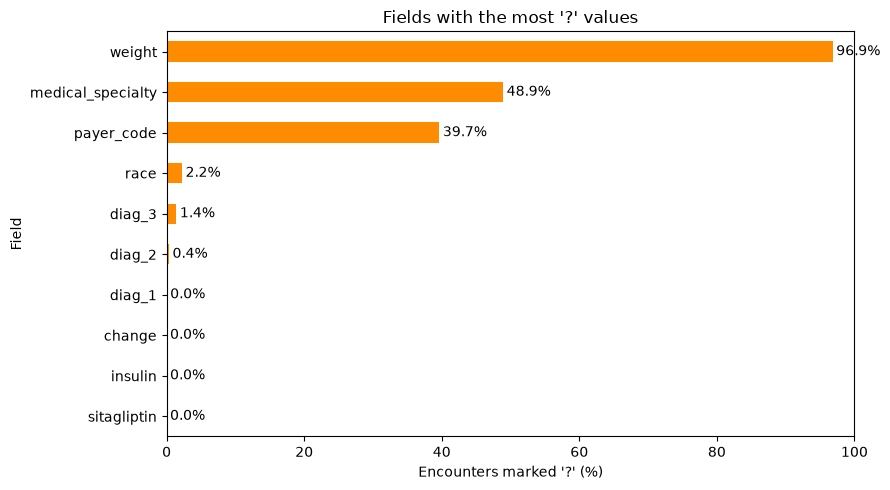

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# The source CSV uses '?' as a missing/unknown marker in several categorical fields.
eda_original_df = input_data_filtered.copy()
unknown_original_pct = (eda_original_df == "?").mean().mul(100).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(9, 5))
unknown_original_pct.plot(kind="barh", color="darkorange", ax=ax)
ax.set(title="Fields with the most '?' values", xlabel="Encounters marked '?' (%)", ylabel="Field")
for position, value in enumerate(unknown_original_pct):
    ax.text(value + 0.5, position, f"{value:.1f}%", va="center")
ax.set_xlim(0, min(100, unknown_original_pct.max() * 1.15))
plt.tight_layout()
plt.show()

- The dataset has 101,766 rows with 50 columns
- 2 identifier columns - encounter_id and patient_nbr
- Fields with value None: 96420 -  max_glu_serum; 84748 -  A1Cresult
- Missing values (marker '?'): weight, medical_specialty, payer_code, race, diag_1, diag_2, diag_3
- From mapping file IDS_mapping.csv, the following are mapped to a discharge disposition id of Hopsice or expired. Hence these are to be excluded per current approach. 

In [21]:
# Define group shuffle split function (to split train/test); pass patient_nbr column to group so that the split does not separate out records for the same patient across training and test sets. 

from sklearn.model_selection import GroupShuffleSplit

def group_train_test_split(df, group_col="patient_nbr", test_size=0.2, random_state=42):
    """Split so every row of a given patient lands in exactly one of train/test."""
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(splitter.split(df, groups=df[group_col]))
    return df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)

In [22]:
# Split train/test and verufy that records for same patient do not cross over sets

train_df, test_df = group_train_test_split(input_data_filtered, "patient_nbr", 0.2)
overlap = set(train_df["patient_nbr"]) & set(test_df["patient_nbr"])
assert not overlap, f"{len(overlap)} patients appear in both sets"

print(f"train: {train_df.shape}, test: {test_df.shape}")
print(f"test row fraction: {len(test_df) / len(input_data_filtered):.3f}")
print("readmitted (train):\n", train_df["readmitted"].value_counts(normalize=True).round(3))
print("readmitted (test):\n", test_df["readmitted"].value_counts(normalize=True).round(3))

train: (79541, 50), test: (19802, 50)
test row fraction: 0.199
readmitted (train):
 readmitted
NO     0.528
>30    0.357
<30    0.114
Name: proportion, dtype: float64
readmitted (test):
 readmitted
NO     0.530
>30    0.358
<30    0.112
Name: proportion, dtype: float64


In [23]:
# create a cleanup function that can be later added to a pipeline. This function performs 2 cleanup actions: 1) It replaces selected values in columns (to begin with these are values that are not measured and are currently marked as None) 2) It then replaces the missing marker '?' with np.nan so that Imputing can be performed on these later

from sklearn.preprocessing import FunctionTransformer

def replace_cleanup(df, replacement_values):
    cleaned_df = df.copy()
    cleaned_df.replace(replacement_values, inplace=True)
    cleaned_df.replace('?', np.nan, inplace=True)
    return cleaned_df


replacement_values = {
    'max_glu_serum': {"None": "not_measured"},
    'A1Cresult': {"None": "not_measured"}

}
cleanup_transformer = FunctionTransformer(
    replace_cleanup, validate=False, kw_args={'replacement_values': replacement_values}
)
input_data_cleaned_train = cleanup_transformer.transform(train_df)
input_data_cleaned_train.isna().sum()

input_data_cleaned_test = cleanup_transformer.transform(test_df)
input_data_cleaned_test.isna().sum()

encounter_id                    0
patient_nbr                     0
race                          418
gender                          0
age                             0
weight                      19146
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                   7837
medical_specialty            9702
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          5
diag_2                         60
diag_3                        250
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [24]:
print(categorical_cols)

['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'sitagliptin', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


## Exploratory visualizations (before encoding)

These plots use the filtered encounter-level data in the training set. They are intended to show class balance, feature distributions, and data-quality patterns before any categorical encoding or imputing. Differences between groups are descriptive and do not imply causation of readmission

In [25]:
import matplotlib.pyplot as plt                  # For visualization
import seaborn as sns                            # For visualization
from pandas.plotting import scatter_matrix

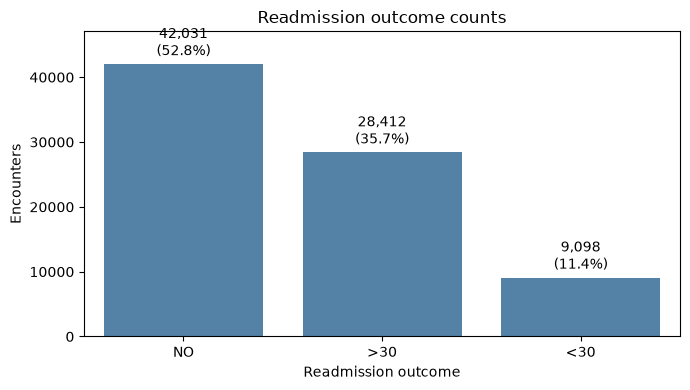

In [26]:
eda_df = input_data_cleaned_train.copy()

target_order = ["NO", ">30", "<30"]
target_counts = eda_df["readmitted"].value_counts().reindex(target_order, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=eda_df, x="readmitted", order=target_order, color="steelblue", ax=ax)
ax.set(title="Readmission outcome counts", xlabel="Readmission outcome", ylabel="Encounters")
for bar, label in zip(ax.patches, target_order):
    count = target_counts[label]
    ax.annotate(f"{count:,}\n({count / len(eda_df):.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
ax.set_ylim(0, target_counts.max() * 1.12)
plt.tight_layout()
plt.show()

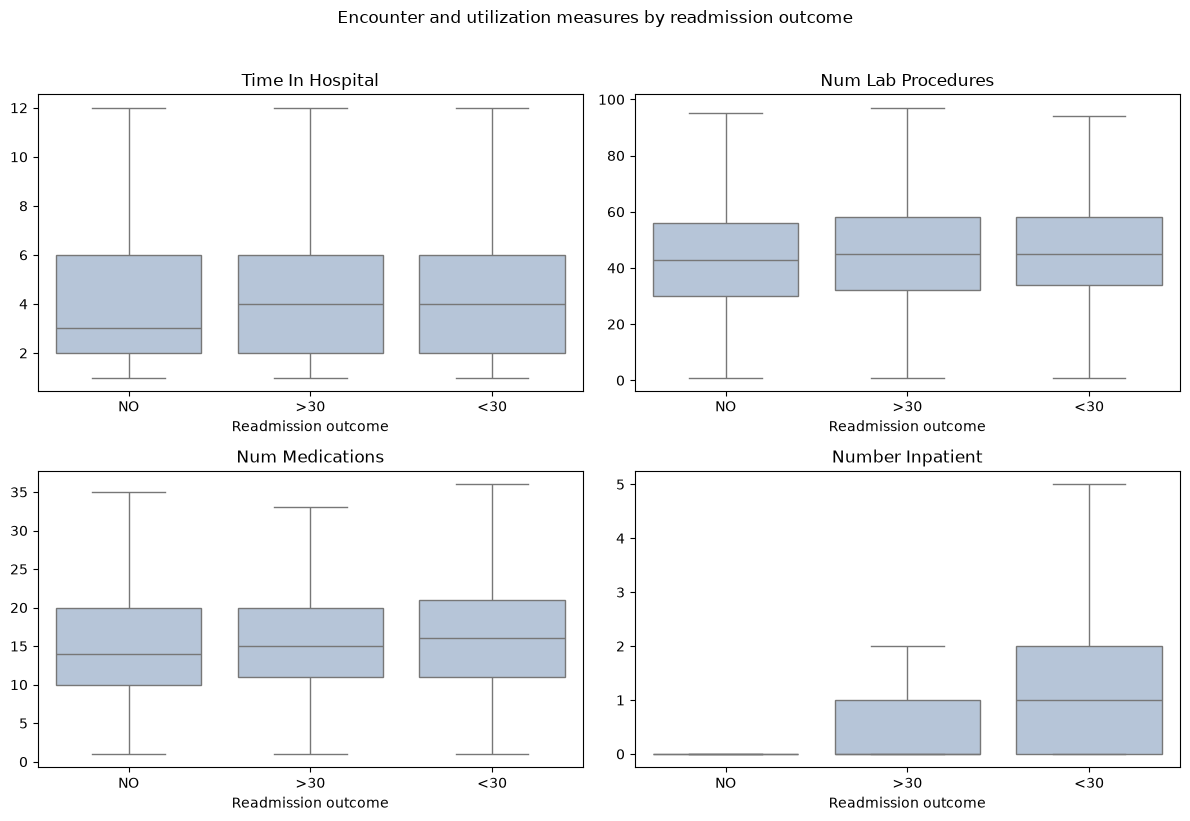

In [27]:
numeric_features_to_plot = [
    "time_in_hospital", "num_lab_procedures", "num_medications", "number_inpatient"
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(numeric_features_to_plot, axes.flat):
    sns.boxplot(data=eda_df, x="readmitted", y=feature, order=target_order,
                showfliers=False, color="lightsteelblue", ax=ax)
    ax.set(title=feature.replace("_", " ").title(), xlabel="Readmission outcome", ylabel="")
fig.suptitle("Encounter and utilization measures by readmission outcome", y=1.02)
plt.tight_layout()
plt.show()

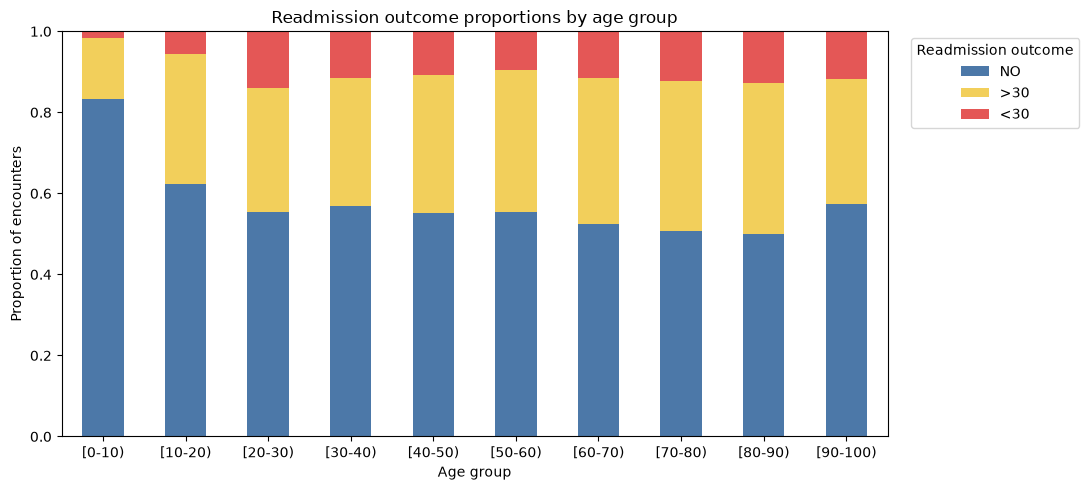

In [28]:
age_order = [f"[{start}-{start + 10})" for start in range(0, 100, 10)]
age_outcome_share = pd.crosstab(eda_df["age"], eda_df["readmitted"], normalize="index")
age_outcome_share = age_outcome_share.reindex(index=age_order, columns=target_order, fill_value=0)

ax = age_outcome_share.plot(kind="bar", stacked=True, figsize=(11, 5),
                            color=["#4c78a8", "#f2cf5b", "#e45756"])
ax.set(title="Readmission outcome proportions by age group", xlabel="Age group",
       ylabel="Proportion of encounters", ylim=(0, 1))
ax.legend(title="Readmission outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
eda_df['weight'].value_counts()

weight
[75-100)     1029
[50-75)       687
[100-125)     492
[125-150)     114
[25-50)        69
[0-25)         39
[150-175)      25
[175-200)      11
>200            3
Name: count, dtype: int64

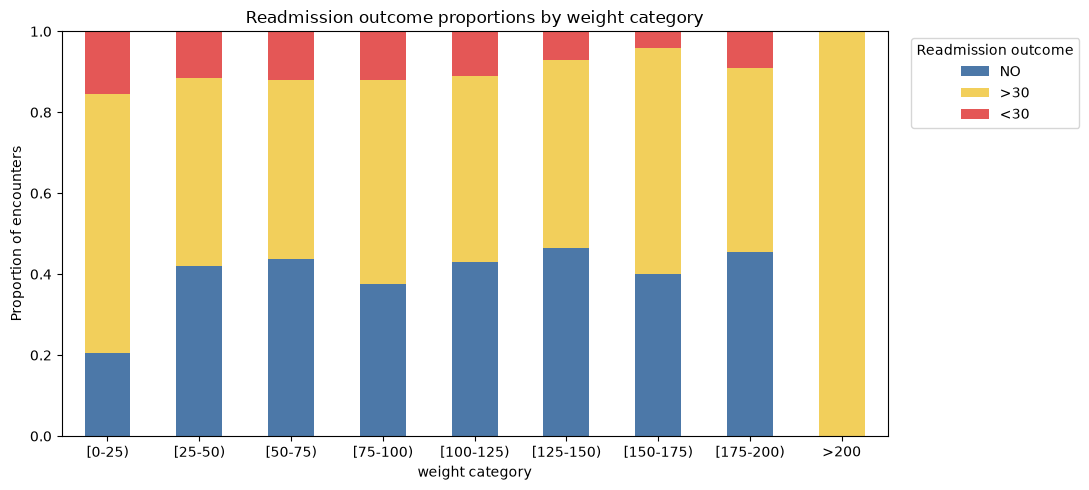

In [30]:
# Plot weights available to check if these have any bearing on readmission. For this, use a filtered copy of the training dataset. As the final input to training will not have NaN values, this is just for visualization and documentation

eda_df_weight_filtered = eda_df.dropna(axis='index', subset=['weight'])

weight_order = [f"[{start}-{start + 25})" for start in range(0, 200, 25)]
weight_order.append(">200")
weight_outcome_share = pd.crosstab(eda_df_weight_filtered["weight"], eda_df_weight_filtered["readmitted"], normalize="index")
weight_outcome_share = weight_outcome_share.reindex(index=weight_order, columns=target_order, fill_value=0)

ax = weight_outcome_share.plot(kind="bar", stacked=True, figsize=(11, 5),
                            color=["#4c78a8", "#f2cf5b", "#e45756"])
ax.set(title="Readmission outcome proportions by weight category", xlabel="weight category",
       ylabel="Proportion of encounters", ylim=(0, 1))
ax.legend(title="Readmission outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
print(f"Encounters by race: \n {eda_df['race'].value_counts()}\n")

race_group = eda_df.dropna(axis='index', subset=['race']).groupby(['race'])
race_group_counts = race_group['readmitted'].value_counts()
race_group_proportions = race_group['readmitted'].value_counts(normalize=True)
race_group_stats = pd.DataFrame({
    'Count': race_group_counts,
    'Proportion': race_group_proportions
})

print(f"Readmitted status by race: \n {race_group_stats}")

Encounters by race: 
 race
Caucasian          59334
AfricanAmerican    15065
Hispanic            1646
Other               1174
Asian                506
Name: count, dtype: int64

Readmitted status by race: 
                             Count  Proportion
race            readmitted                   
AfricanAmerican NO           8028    0.532891
                >30          5284    0.350747
                <30          1753    0.116362
Asian           NO            321    0.634387
                >30           130    0.256917
                <30            55    0.108696
Caucasian       NO          30780    0.518758
                >30         21705    0.365810
                <30          6849    0.115431
Hispanic        NO            948    0.575942
                >30           525    0.318955
                <30           173    0.105103
Other           NO            708    0.603066
                >30           348    0.296422
                <30           118    0.100511


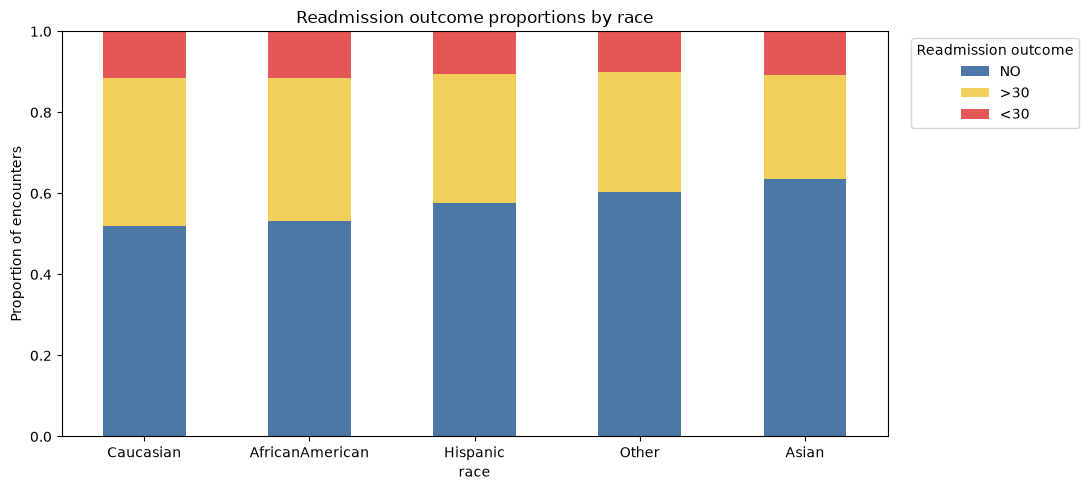

In [32]:
# Plot race to check if these have any bearing on readmission. For this, use a filtered copy of the training dataset. As the final input to training will not have NaN values, this is just for visualization and documentation

eda_df_race_filtered = eda_df.dropna(axis='index', subset=['race'])

race_order = ["Caucasian", "AfricanAmerican", "Hispanic", "Other", "Asian"]
race_outcome_share = pd.crosstab(eda_df_race_filtered["race"], eda_df_race_filtered["readmitted"], normalize="index")
race_outcome_share = race_outcome_share.reindex(index=race_order, columns=target_order, fill_value=0)

ax = race_outcome_share.plot(kind="bar", stacked=True, figsize=(11, 5),
                            color=["#4c78a8", "#f2cf5b", "#e45756"])
ax.set(title="Readmission outcome proportions by race", xlabel="race",
       ylabel="Proportion of encounters", ylim=(0, 1))
ax.legend(title="Readmission outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
pd.set_option('display.max_rows', 300)

In [34]:
eda_df_med_specialty_filtered = eda_df.dropna(axis='index', subset=['medical_specialty'])
eda_df_payer_code_filtered = eda_df.dropna(axis='index', subset=['payer_code'])
eda_df_diag_1_filtered = eda_df.dropna(axis='index', subset=['diag_1'])
eda_df_diag_2_filtered = eda_df.dropna(axis='index', subset=['diag_2'])
eda_df_diag_3_filtered = eda_df.dropna(axis='index', subset=['diag_3'])

print(f"Number of unique valid values:\n")
print(f"medical_specialty: {eda_df['medical_specialty'].nunique()}")
print(f"payer_code: {eda_df['payer_code'].nunique()}")
print(f"diag_1: {eda_df['diag_1'].nunique()}")
print(f"diag_2: {eda_df['diag_2'].nunique()}")
print(f"diag_3: {eda_df['diag_3'].nunique()}")


Number of unique valid values:

medical_specialty: 72
payer_code: 17
diag_1: 700
diag_2: 718
diag_3: 760


In [35]:
#print(f"Count of encounters by medical_specialty: \n {eda_df_med_specialty_filtered['medical_specialty'].value_counts()}\n")
print(f"Count of encounters by medical_specialty: \n {eda_df['medical_specialty'].value_counts()}\n")

med_specialty_group = eda_df_med_specialty_filtered.groupby(['medical_specialty'])

med_specialty_group_counts = med_specialty_group['readmitted'].value_counts()
med_specialty_group_proportions = med_specialty_group['readmitted'].value_counts(normalize=True)
med_specialty_group_stats = pd.DataFrame({
    'Count': med_specialty_group_counts,
    'Proportion': med_specialty_group_proportions
})

print(f"Readmitted status by med_specialty: \n {med_specialty_group_stats}")
print(f"Readmitted status - InternalMedicine: \n {med_specialty_group_stats.loc['InternalMedicine']}")

Count of encounters by medical_specialty: 
 medical_specialty
InternalMedicine                        11463
Emergency/Trauma                         5989
Family/GeneralPractice                   5766
Cardiology                               4269
Surgery-General                          2431
Nephrology                               1220
Orthopedics                              1087
Orthopedics-Reconstructive                990
Radiologist                               884
Pulmonology                               707
Psychiatry                                671
Urology                                   543
ObstetricsandGynecology                   516
Surgery-Cardiovascular/Thoracic           505
Surgery-Vascular                          416
Gastroenterology                          415
Surgery-Neuro                             352
PhysicalMedicineandRehabilitation         308
Oncology                                  254
Pediatrics                                206
Neurology         

In [36]:
print(f"Count of encounters by payer_code: \n {eda_df['payer_code'].value_counts()}\n")

payer_code_group = eda_df_payer_code_filtered.groupby(['payer_code'])

payer_code_group_counts = payer_code_group['readmitted'].value_counts()
payer_code_group_proportions = payer_code_group['readmitted'].value_counts(normalize=True)
payer_code_group_stats = pd.DataFrame({
    'Count': payer_code_group_counts,
    'Proportion': payer_code_group_proportions
})

print(f"Readmitted status by payer_code: \n {payer_code_group_stats}")


Count of encounters by payer_code: 
 payer_code
MC    25030
HM     4966
SP     3933
BC     3670
MD     2823
CP     1979
UN     1930
CM     1498
OG      815
PO      471
DM      455
CH      109
WC      109
OT       76
MP       69
SI       46
FR        1
Name: count, dtype: int64

Readmitted status by payer_code: 
                        Count  Proportion
payer_code readmitted                   
BC         NO           2279    0.620981
           >30          1047    0.285286
           <30           344    0.093733
CH         NO             74    0.678899
           >30            25    0.229358
           <30            10    0.091743
CM         NO            819    0.546729
           >30           521    0.347797
           <30           158    0.105474
CP         NO           1173    0.592724
           >30           645    0.325922
           <30           161    0.081354
DM         NO            211    0.463736
           >30           185    0.406593
           <30            59  

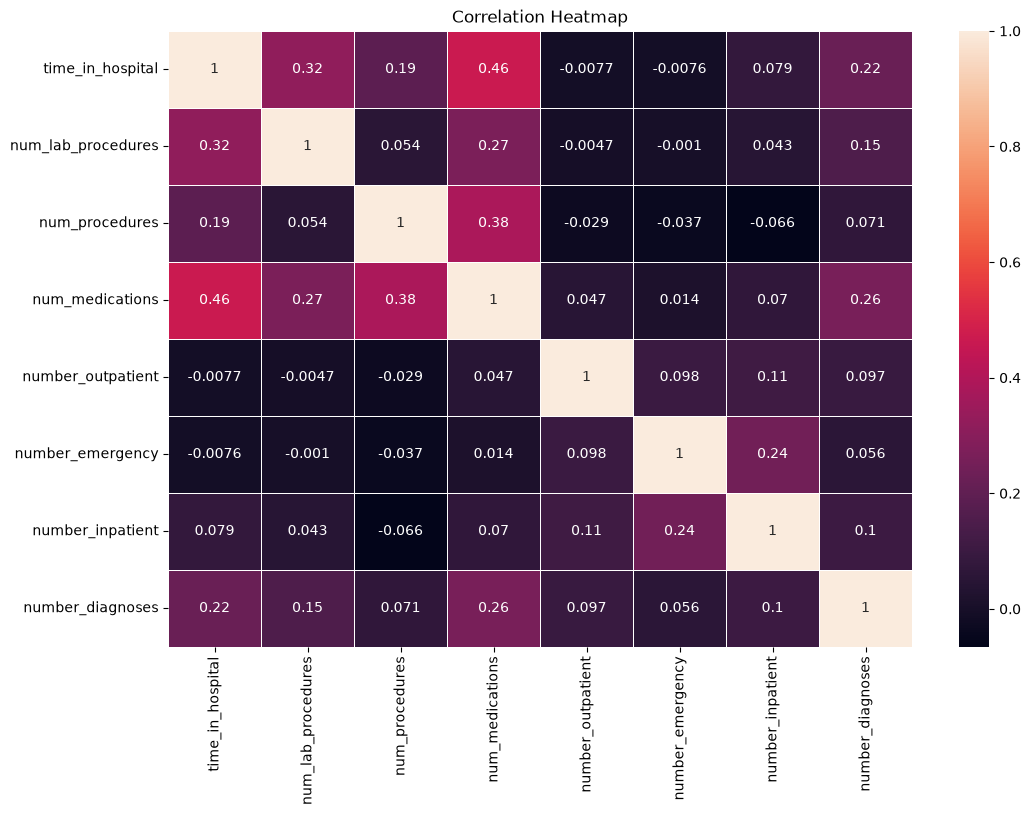

In [37]:
# Correlation Matrix
corr_matrix = input_data_cleaned_train[numerical_cols].corr()
plt.figure(figsize=(12, 8))  # Set the figure size
sns.heatmap(corr_matrix, annot=True, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

#### Observations
- Class Imbalance: The target classes are unevenly represented. Compare suitable metrics and class weighting.
- Scale: Utilization features have different scales. Scaling/normalization can be done based on model needs.
- The following categorical fields have NaN values.  
    - weight (Around 97% values are missing. Train and compare models with and without the 'weight' feature)
    - medical_specialty
    - payer_code
    - race
    - diag_1/diag_2/diag_3
- The below are some of the numerical fields that show some correlation - these describe feature-feature associations and not predictive significance : 
    1) num_procedures and num_medications
    2) num_lab_procedures and num_medications
    2) number_inpatient and number_emergency
    3) time_in_hospital with num_medications, number_diagnoses and num_lab_procedures
    4) num_medications and number_diagnoses
   

### Split training and test datasets into input and target

In [38]:
# set target positive and negative values. <30 -> 1, other values -> 0

def set_target(df):
    target_df = df.copy()
    pos_filt = (target_df['readmitted'] == '<30')
    neg_filt = (target_df['readmitted'] != '<30')
    target_df.loc[pos_filt, 'target'] = 1
    target_df.loc[neg_filt, 'target'] = 0
    return target_df


In [39]:
print("Train:")
print(f"readmitted counts before setting target values: {train_df['readmitted']. value_counts()}")
train_df = set_target(train_df)
print(f"readmitted counts after setting target values: {train_df['readmitted']. value_counts()}\n")
print(f"target counts: {train_df['target']. value_counts()}\n")

print("Test:")
print(f"readmitted counts before setting target values: {test_df['readmitted']. value_counts()}")
test_df = set_target(test_df)
print(f"target counts: {test_df['target']. value_counts()}")

Train:
readmitted counts before setting target values: readmitted
NO     42031
>30    28412
<30     9098
Name: count, dtype: int64
readmitted counts after setting target values: readmitted
NO     42031
>30    28412
<30     9098
Name: count, dtype: int64

target counts: target
0.0    70443
1.0     9098
Name: count, dtype: int64

Test:
readmitted counts before setting target values: readmitted
NO     10496
>30     7090
<30     2216
Name: count, dtype: int64
target counts: target
0.0    17586
1.0     2216
Name: count, dtype: int64


In [40]:
# Split into input and target variables

y_train, y_test = train_df['target'], test_df['target']
X_train, X_test = train_df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted', 'target']), test_df.drop(columns=['encounter_id', 'patient_nbr', 'readmitted', 'target'])

### Data preprocessing/Feature engineering
- Impute NaN values
- Encode all categorical variables
- Scale all numerical variables

In [41]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [42]:
print(y_train.value_counts())

target
0.0    70443
1.0     9098
Name: count, dtype: int64


In [43]:
print(f"Categorical columns: \n {categorical_cols}\n\n")
print(f"Numerical columns: \n {numerical_cols}")

print(f"X columns: \n {X_train.columns}\n\n")

for x in X_train.columns:
    if x not in set(categorical_cols):
        print(f"Not categorical: {x}") 


Categorical columns: 
 ['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'sitagliptin', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


Numerical columns: 
 ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
X columns: 
 Index(['race', 'gender', 'age', 'weight', 'admission_type_id',
       'discharge_disposition_id', 'admission_source_id', 'time_in_hospital',
       'payer_code', 'medi

In [44]:
# Define pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold




# Categorical columns: Clean up specific missing values, impute all other NaN values, perform OneHotencoding on all categorical columns

cat_pipeline = Pipeline([
    ("replace_cleanup", cleanup_transformer),
    ("cat_imputer", SimpleImputer(strategy="constant", fill_value='not_recorded')),
    ("cat_encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20))
])

# Numerical columns: Impute missing values (if any) using Median, StandardScaler (exclude for decision trees)

num_pipeline = Pipeline([
    ("num_imputer", SimpleImputer(strategy="median")),
    ("stdscaler", StandardScaler())
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, numerical_cols),
    ("cat", cat_pipeline, categorical_cols)
])
#Define groups for splitting by patient number so that records for the same patient remain within the same group



### Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, precision_score


log_reg_model = Pipeline([
    ("preprocess", preprocessing),
    ("log_reg", LogisticRegression(
        solver="liblinear"
    ))
])


pat_ids = train_df['patient_nbr'] 
cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)


param_grid = {
    'log_reg__C': [0.01, 0.1, 1.0],
    'log_reg__l1_ratio': [0],             # 0 = L2, 1 = L1
    'log_reg__class_weight': [None, 'balanced']
}

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': 'f1',
    'pr_auc': 'average_precision'           
}



log_reg_grid_search = GridSearchCV(
    verbose=2,
    estimator=log_reg_model,
    param_grid=param_grid,
    cv=cv_splitter,
    scoring=scoring,
    refit='pr_auc',           
    error_score='raise',
    n_jobs=-1
)

log_reg_grid_search.fit(X_train, y_train, groups=pat_ids)

print(f"Optimal Parameters: {log_reg_grid_search.best_params_}")
print(f"Best Group-Aware Cross-Validation Score: {log_reg_grid_search.best_score_:.4f}")


Fitting 5 folds for each of 6 candidates, totalling 30 fits


Optimal Parameters: {'log_reg__C': 0.1, 'log_reg__class_weight': None, 'log_reg__l1_ratio': 0}
Best Group-Aware Cross-Validation Score: 0.2188


In [46]:
cv_results = pd.DataFrame(log_reg_grid_search.cv_results_)
metric_cols = [f"{stat}_test_{m}" for m in scoring for stat in ("mean", "std")]
cv_results[["params", *metric_cols]].sort_values("mean_test_pr_auc", ascending=False)

,params,mean_test_accuracy,std_test_accuracy,mean_test_precision,std_test_precision,mean_test_recall,std_test_recall,mean_test_f1,std_test_f1,mean_test_pr_auc,std_test_pr_auc
2,"{'log_reg__C': 0.1, 'log_reg__class_weight': N...",0.885594,0.000480,0.499810,0.054807,0.018905,0.002635,0.036410,0.004967,0.218848,0.004012
1,"{'log_reg__C': 0.01, 'log_reg__class_weight': ...",0.668850,0.006371,0.185971,0.005334,0.560890,0.011517,0.279316,0.007307,0.217882,0.003023
0,"{'log_reg__C': 0.01, 'log_reg__class_weight': ...",0.885656,0.000386,0.507976,0.054175,0.015717,0.002470,0.030472,0.004697,0.217471,0.003582
3,"{'log_reg__C': 0.1, 'log_reg__class_weight': '...",0.663067,0.006631,0.182419,0.004522,0.558581,0.012079,0.275004,0.006224,0.216717,0.003488
4,"{'log_reg__C': 1.0, 'log_reg__class_weight': N...",0.885292,0.000603,0.475760,0.060723,0.022203,0.002213,0.042388,0.004066,0.213439,0.004748
5,"{'log_reg__C': 1.0, 'log_reg__class_weight': '...",0.655398,0.006616,0.177900,0.003880,0.555614,0.010439,0.269488,0.005232,0.212148,0.003880


In [47]:
from collections import defaultdict

# Results per model: best hyperparameters, then the comparison metrics computed in the comparison section below
hosp_readmission_risk_model_metrics = defaultdict(dict)


def store_metrics(model_name, model_metrics):
    """Add values to a model's entry in the shared results dictionary."""
    hosp_readmission_risk_model_metrics[model_name].update(model_metrics)


store_metrics("Logistic Regression", {"Best Params": log_reg_grid_search.best_params_})


### Decision Tree

The decision tree uses the same grouped cross-validation folds and scoring metrics as logistic regression. Numeric features are imputed but not standardized because tree splits are scale-independent.

In [48]:
from sklearn.tree import DecisionTreeClassifier


tree_num_pipeline = Pipeline([
    ("num_imputer", SimpleImputer(strategy="median"))
])

tree_preprocessing = ColumnTransformer([
    ("num", tree_num_pipeline, numerical_cols),
    ("cat", cat_pipeline, categorical_cols)
])

decision_tree_model = Pipeline([
    ("preprocess", tree_preprocessing),
    ("decision_tree", DecisionTreeClassifier(random_state=42))
])

tree_param_grid = {
    "decision_tree__max_depth": [5, 10, None],
    "decision_tree__min_samples_leaf": [10, 50],
    "decision_tree__class_weight": [None, "balanced"]
}

decision_tree_grid_search = GridSearchCV(
    verbose=2,
    estimator=decision_tree_model,
    param_grid=tree_param_grid,
    cv=cv_splitter,
    scoring=scoring,
    refit="pr_auc",
    error_score="raise",
    n_jobs=-1
)

decision_tree_grid_search.fit(X_train, y_train, groups=pat_ids)
print(f"Optimal Parameters: {decision_tree_grid_search.best_params_}")
print(f"Best Group-Aware Cross-Validation Score: {decision_tree_grid_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Optimal Parameters: {'decision_tree__class_weight': None, 'decision_tree__max_depth': 10, 'decision_tree__min_samples_leaf': 50}
Best Group-Aware Cross-Validation Score: 0.2004


In [49]:
store_metrics("Decision Tree", {"Best Params": decision_tree_grid_search.best_params_})


### Random Forest

The random forest evaluates an ensemble of decision trees using the same grouped cross-validation folds and scoring metrics. It reuses the tree preprocessing because numeric scaling is not required for tree-based models.

In [50]:
from sklearn.ensemble import RandomForestClassifier


random_forest_model = Pipeline([
    ("preprocess", tree_preprocessing),
    ("random_forest", RandomForestClassifier(
        n_estimators=50,
        random_state=42,
        n_jobs=1
    ))
])

random_forest_param_grid = {
    "random_forest__max_depth": [10],
    "random_forest__min_samples_leaf": [10],
    "random_forest__class_weight": [None, "balanced"]
}

random_forest_grid_search = GridSearchCV(
    verbose=2,
    estimator=random_forest_model,
    param_grid=random_forest_param_grid,
    cv=cv_splitter,
    scoring=scoring,
    refit="pr_auc",
    error_score="raise",
    n_jobs=-1
)

random_forest_grid_search.fit(X_train, y_train, groups=pat_ids)
print(f"Optimal Parameters: {random_forest_grid_search.best_params_}")
print(f"Best Group-Aware Cross-Validation Score: {random_forest_grid_search.best_score_:.4f}")

Fitting 5 folds for each of 2 candidates, totalling 10 fits


Optimal Parameters: {'random_forest__class_weight': None, 'random_forest__max_depth': 10, 'random_forest__min_samples_leaf': 10}
Best Group-Aware Cross-Validation Score: 0.2151


In [51]:
store_metrics("Random Forest", {"Best Params": random_forest_grid_search.best_params_})


### XGBoost

Gradient-boosted trees use the same grouped cross-validation folds, tree preprocessing and scoring as the previous models. The search covers tree depth, learning rate and number of trees (a lower learning rate needs more trees), regularization, row/column subsampling and class weighting (`scale_pos_weight` of 1 or the negative:positive ratio). A randomized search is used because the grid is too large to search exhaustively.

In [52]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

neg_pos_ratio = float((y_train == 0).sum() / (y_train == 1).sum())

xgboost_model = Pipeline([
    ("preprocess", tree_preprocessing),
    ("xgboost", XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=42, n_jobs=1))
])

xgboost_param_distributions = {
    "xgboost__n_estimators": [200, 400, 800],
    "xgboost__learning_rate": [0.01, 0.03, 0.05],
    "xgboost__max_depth": [2, 3, 4, 6],
    "xgboost__min_child_weight": [1, 10, 50],
    "xgboost__subsample": [0.7, 0.9],
    "xgboost__colsample_bytree": [0.3, 0.6],
    "xgboost__reg_lambda": [1, 10],
    "xgboost__scale_pos_weight": [1, neg_pos_ratio]
}

xgboost_search = RandomizedSearchCV(
    verbose=2,
    estimator=xgboost_model,
    param_distributions=xgboost_param_distributions,
    n_iter=30,
    cv=cv_splitter,
    scoring=scoring,
    refit="pr_auc",
    error_score="raise",
    random_state=42,
    n_jobs=-1
)

xgboost_search.fit(X_train, y_train, groups=pat_ids)
print(f"Optimal Parameters: {xgboost_search.best_params_}")
print(f"Best Group-Aware Cross-Validation Score: {xgboost_search.best_score_:.4f}")
store_metrics("XGBoost", {"Best Params": xgboost_search.best_params_})


Fitting 5 folds for each of 30 candidates, totalling 150 fits


Optimal Parameters: {'xgboost__subsample': 0.9, 'xgboost__scale_pos_weight': 1, 'xgboost__reg_lambda': 10, 'xgboost__n_estimators': 400, 'xgboost__min_child_weight': 10, 'xgboost__max_depth': 6, 'xgboost__learning_rate': 0.05, 'xgboost__colsample_bytree': 0.3}
Best Group-Aware Cross-Validation Score: 0.2340


In [53]:
xgboost_cv_results = pd.DataFrame(xgboost_search.cv_results_)
xgboost_cv_results[["params", "mean_test_pr_auc", "std_test_pr_auc"]].sort_values("mean_test_pr_auc", ascending=False).head(10)


,params,mean_test_pr_auc,std_test_pr_auc
25,"{'xgboost__subsample': 0.9, 'xgboost__scale_po...",0.234010,0.003959
20,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.233932,0.004117
22,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.233366,0.004125
16,"{'xgboost__subsample': 0.9, 'xgboost__scale_po...",0.232517,0.004266
9,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.232048,0.003625
26,"{'xgboost__subsample': 0.9, 'xgboost__scale_po...",0.230049,0.002916
23,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.229096,0.005702
17,"{'xgboost__subsample': 0.9, 'xgboost__scale_po...",0.228087,0.003189
24,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.227479,0.003372
14,"{'xgboost__subsample': 0.7, 'xgboost__scale_po...",0.227380,0.002949


### Neural Network (MLP)

A multilayer perceptron uses the same grouped folds and scoring. Unlike the tree models it needs scaled numeric inputs, so it reuses the logistic regression `preprocessing` (standardized numerics plus one-hot categoricals). scikit-learn's `MLPClassifier` is used here, with early stopping on an internal validation split to limit overfitting. It does not support class weights, so the output probabilities are left uncalibrated and the decision threshold is chosen later from out-of-fold predictions like the other models.

In [54]:
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

mlp_model = Pipeline([
    ("preprocess", preprocessing),
    ("mlp", MLPClassifier(
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5,
        max_iter=100,
        random_state=42
    ))
])

mlp_param_grid = {
    "mlp__hidden_layer_sizes": [(64,), (128, 64)],
    "mlp__alpha": [0.01, 0.1, 1.0]
}

mlp_grid_search = GridSearchCV(
    verbose=2,
    estimator=mlp_model,
    param_grid=mlp_param_grid,
    cv=cv_splitter,
    scoring=scoring,
    refit="pr_auc",
    error_score="raise",
    n_jobs=-1
)

mlp_grid_search.fit(X_train, y_train, groups=pat_ids)
print(f"Optimal Parameters: {mlp_grid_search.best_params_}")
print(f"Best Group-Aware Cross-Validation Score: {mlp_grid_search.best_score_:.4f}")
store_metrics("Neural Network (MLP)", {"Best Params": mlp_grid_search.best_params_})


Fitting 5 folds for each of 6 candidates, totalling 30 fits


Optimal Parameters: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (64,)}
Best Group-Aware Cross-Validation Score: 0.2236


### Model comparison: threshold selection and capacity-based metrics

With about 11% positives, models trained on the raw class balance (tree models in particular) rarely output a probability above 0.5, so precision and recall at the default 0.5 cutoff are not comparable across models (Random Forest predicted no positives at all, giving precision = 0, even though its ranking quality is competitive). All models are therefore compared here on the same footing using out-of-fold (OOF) predictions from the same grouped folds:
- **Threshold-free metrics:** ROC-AUC and PR-AUC (the PR-AUC random-guess baseline equals the base rate).
- **Threshold chosen from OOF predictions:** the cutoff that maximizes F1 on the training OOF probabilities. It is never tuned on the test set. Overall accuracy, precision, recall and F1 are reported at this cutoff. Accuracy alone is misleading here because predicting 'not readmitted' for everyone already scores 1 - base rate (about 0.886).
- **Capacity-based metrics:** precision, recall and lift when only the top 5%, 10% or 20% highest-risk encounters can be followed up. Lift = precision in the flagged group / base rate.

The test set is not used in this section.

In [55]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

candidate_searches = {
    "Logistic Regression": log_reg_grid_search,
    "Decision Tree": decision_tree_grid_search,
    "Random Forest": random_forest_grid_search,
    "XGBoost": xgboost_search,
    "Neural Network (MLP)": mlp_grid_search,
}

# Out-of-fold probabilities: each training encounter is scored by a model that did not see its patient.
# Re-uses cv_splitter (fixed random_state), so the folds match the grid searches.
oof_probabilities = {}
for model_name, search in candidate_searches.items():
    oof_probabilities[model_name] = cross_val_predict(
        clone(search.best_estimator_),
        X_train, y_train,
        cv=cv_splitter, groups=pat_ids,
        method="predict_proba", n_jobs=-1
    )[:, 1]


In [56]:
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)

CAPACITY_FRACTIONS = [0.05, 0.10, 0.20]


def select_f1_threshold(y_true, y_score):
    """Probability cutoff that maximizes F1 on the given scores (use OOF training scores only)."""
    precision, recall, thresholds = precision_recall_curve(y_true, y_score)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def capacity_metrics(y_true, y_score, fractions=CAPACITY_FRACTIONS):
    """Precision, recall and lift when only the top `fraction` of highest-scored encounters are flagged."""
    y_true = np.asarray(y_true)
    order = np.argsort(-np.asarray(y_score), kind="stable")
    base_rate = y_true.mean()
    metrics = {}
    for fraction in fractions:
        n_flagged = max(1, int(round(fraction * len(y_true))))
        hits = y_true[order[:n_flagged]].sum()
        precision = hits / n_flagged
        metrics[f"Precision@Top{fraction:.0%}"] = precision
        metrics[f"Recall@Top{fraction:.0%}"] = hits / y_true.sum()
        metrics[f"Lift@Top{fraction:.0%}"] = precision / base_rate
    return metrics


def evaluate_scores(y_true, y_score, threshold):
    """Threshold-free, fixed-threshold and capacity-based metrics for one set of predicted probabilities."""
    y_pred = (np.asarray(y_score) >= threshold).astype(int)
    metrics = {
        "Base Rate": float(np.mean(y_true)),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC": average_precision_score(y_true, y_score),
        "Threshold": threshold,
        "Flagged@Threshold": float(y_pred.mean()),
        "Accuracy@Threshold": accuracy_score(y_true, y_pred),
        "Precision@Threshold": precision_score(y_true, y_pred, zero_division=0),
        "Recall@Threshold": recall_score(y_true, y_pred),
        "F1@Threshold": f1_score(y_true, y_pred),
    }
    metrics.update(capacity_metrics(y_true, y_score))
    return metrics


In [57]:
oof_thresholds = {name: select_f1_threshold(y_train, scores) for name, scores in oof_probabilities.items()}
oof_metrics = {name: evaluate_scores(y_train, scores, oof_thresholds[name]) for name, scores in oof_probabilities.items()}

for name, metrics in oof_metrics.items():
    store_metrics(name, metrics)

pd.DataFrame(oof_metrics).T.sort_values("PR-AUC", ascending=False).round(3)


,Base Rate,ROC-AUC,PR-AUC,Threshold,Flagged@Threshold,Accuracy@Threshold,Precision@Threshold,Recall@Threshold,F1@Threshold,Precision@Top5%,Recall@Top5%,Lift@Top5%,Precision@Top10%,Recall@Top10%,Lift@Top10%,Precision@Top20%,Recall@Top20%,Lift@Top20%
XGBoost,0.114,0.679,0.234,0.141,0.245,0.746,0.215,0.462,0.294,0.333,0.146,2.911,0.277,0.242,2.425,0.228,0.398,1.991
Neural Network (MLP),0.114,0.671,0.222,0.147,0.262,0.731,0.205,0.470,0.286,0.316,0.138,2.763,0.261,0.228,2.284,0.223,0.389,1.946
Logistic Regression,0.114,0.666,0.218,0.141,0.228,0.754,0.212,0.421,0.282,0.311,0.136,2.715,0.264,0.231,2.306,0.219,0.383,1.914
Random Forest,0.114,0.667,0.214,0.128,0.253,0.736,0.205,0.452,0.282,0.292,0.128,2.552,0.261,0.229,2.285,0.220,0.384,1.921
Decision Tree,0.114,0.645,0.202,0.120,0.315,0.687,0.184,0.505,0.269,0.285,0.125,2.493,0.240,0.209,2.095,0.206,0.360,1.798


In [58]:
# Test set evaluation ===> To be performed once, after model selection. Uses the threshold fixed from the OOF training predictions.

#best_name = "..."   # selected model from the comparison table above
#best_model = candidate_searches[best_name].best_estimator_      # already refit on the full training set
#test_scores = best_model.predict_proba(X_test)[:, 1]

#pd.Series(evaluate_scores(y_test, test_scores, oof_thresholds[best_name])).round(4)


#### References
Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). Diabetes 130-US Hospitals for Years 1999-2008 [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. BioMed Research International, 2014, Article 781670. https://doi.org/10.1155/2014/781670